# 05 · Where Do SEA Booms Come From, and How Do They Spread? (Phase P5)

Research questions **RQ4** (origin) and **RQ5** (spread within SEA). Hypotheses frozen in `PREREGISTRATION.md` §5:

| # | Hypothesis | Test |
|---|---|---|
| **H6a** | SEA booms come from **China as often as from the US** | two-sided binomial test on origin counts |
| **H6b** | China-origin models reach SEA with a **shorter lag** | Mann–Whitney on origin → SEA lags |
| **H7** | Booms appear first in **Singapore or Indonesia**, then spread in a **consistent order** | Kendall's W on country ranks; SG/ID-first count vs chance |

**Data (deviation, logged):** the catalogue can't date most digital takeoffs (they predate 2019) or any takeoffs in the
US, China or India. So P5 uses a hand-built **launch table** (`drivers/launches.csv`): the year the first scaled,
app-based player in each category launched in each country, for 6 categories × (6 SEA + US + China + India).
Every date has a source; dates with two sources are "verified". All tests run **twice**: all dates, and
verified-only.

**What a launch date is not:** it is when a category *arrived*, not when it *took off*. Launch timing is the
standard proxy in cross-country diffusion research, where sales data are unavailable.

In [1]:
import sys, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))
from drivers.config import PROC, FIG, ROOT, NAME, TIER_A
warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
RNG = np.random.default_rng(20261011)
NAME_ALL = {**NAME, "USA": "United States", "CHN": "China", "IND": "India"}
ORIG = ["USA", "CHN", "IND"]

L_all = pd.read_csv(ROOT / "drivers" / "launches.csv")
print(L_all.groupby("category").status.value_counts().unstack(fill_value=0))
L_all.pivot(index="category", columns="iso3", values="launch_year")[ORIG + TIER_A].astype("Int64")

status                 single_source  verified
category                                      
bnpl                               1         8
crypto_exchange                    2         6
ecommerce_marketplace              2         7
food_delivery                      3         6
mobile_wallet                      3         6
ride_hailing                       2         7


iso3,USA,CHN,IND,IDN,MYS,PHL,SGP,THA,VNM
category,,,,,,,,,
bnpl,2012,2015,2015,2016,2020,2017,2019,2021,2019
crypto_exchange,2012,2011,2014,2014,<NA>,2014,2014,2014,2015
ecommerce_marketplace,1995,2003,2007,2009,2012,2012,2012,2012,2012
food_delivery,2004,2008,2014,2012,2012,2012,2012,2012,2011
mobile_wallet,2009,2004,2014,2007,2017,2004,2016,2013,2010
ride_hailing,2010,2012,2010,2014,2012,2013,2013,2013,2014


## 1 · Origin attribution
**Origin of a category** = whichever of US / China / India launched it first. **SEA-native** if an SEA country
launched it in the same year or earlier than all three. **Lag** = SEA launch year − origin launch year (per country).

In [2]:
def attribution(L):
    rows = []
    for cat, g in L.groupby("category"):
        y = g.set_index("iso3").launch_year
        o = y.reindex(ORIG).dropna(); s = y.reindex(TIER_A).dropna()
        if o.empty or s.empty: continue
        first_o = o.min(); first_s = s.min()
        origins = sorted(o[o == first_o].index)
        origin = "SEA-native" if first_s <= first_o else "/".join(origins)
        rows.append(dict(category=cat, origin=origin, origin_year=int(first_o), first_sea=int(first_s),
                         first_sea_countries=",".join(sorted(s[s == first_s].index)), lag_to_first_sea=int(first_s - first_o),
                         lag_to_last_sea=int(s.max() - first_o), sea_spread_years=int(s.max() - first_s)))
    return pd.DataFrame(rows).set_index("category")

ATT = {"all dates": attribution(L_all), "verified only": attribution(L_all[L_all.status == "verified"])}
ATT["all dates"]

,origin,origin_year,first_sea,first_sea_countries,lag_to_first_sea,lag_to_last_sea,sea_spread_years
category,,,,,,,
bnpl,USA,2012,2016,IDN,4,9,5
crypto_exchange,CHN,2011,2014,"IDN,PHL,SGP,THA",3,4,1
ecommerce_marketplace,USA,1995,2009,IDN,14,17,3
food_delivery,USA,2004,2011,VNM,7,8,1
mobile_wallet,SEA-native,2004,2004,PHL,0,13,13
ride_hailing,IND/USA,2010,2012,MYS,2,4,2


In [3]:
ATT["verified only"]

,origin,origin_year,first_sea,first_sea_countries,lag_to_first_sea,lag_to_last_sea,sea_spread_years
category,,,,,,,
bnpl,USA,2012,2016,IDN,4,9,5
crypto_exchange,CHN,2011,2014,"IDN,PHL,SGP",3,3,0
ecommerce_marketplace,USA,1995,2009,IDN,14,17,3
food_delivery,USA,2004,2012,"MYS,PHL,SGP,THA",8,8,0
ride_hailing,SEA-native,2012,2012,MYS,0,2,2


## 2 · H6a: China as often as the US?
A two-sided binomial test of China-origin vs US-origin counts. Categories with tied origins count half to each.
SEA-native categories are excluded from this comparison. **Supported if** equal shares are not rejected, but with
4–6 categories "not rejected" is weak evidence either way.

In [4]:
def h6a(A):
    us = sum((o == "USA") + 0.5 * ("USA" in o and "/" in o) for o in A.origin)
    cn = sum((o == "CHN") + 0.5 * ("CHN" in o and "/" in o) for o in A.origin)
    n = int(round(us + cn)); k = int(round(cn))
    p = stats.binomtest(k, n, 0.5).pvalue if n else np.nan
    return dict(US_origin=us, China_origin=cn, India_origin=sum("IND" in o for o in A.origin),
                SEA_native=sum(o == "SEA-native" for o in A.origin), binomial_p=round(p, 3) if n else np.nan)
pd.DataFrame({k: h6a(v) for k, v in ATT.items()}).T

,US_origin,China_origin,India_origin,SEA_native,binomial_p
all dates,3.5,1.0,1.0,1.0,0.625
verified only,3.0,1.0,0.0,1.0,0.625


## 3 · H6b: do China-origin models arrive faster?
Country-level lags (each SEA country's launch − origin launch), China-origin vs US-origin categories, by Mann–Whitney
(one-sided: China shorter). Lags within a category are not independent, so this is **descriptive**.
**Confound:** China-origin categories (crypto exchanges) are recent, and *everything* diffuses faster in recent years
(see §5).

In [5]:
def lags(L, A):
    rows = []
    for cat, a in A.iterrows():
        if a.origin == "SEA-native": continue
        for _, r in L[(L.category == cat) & L.iso3.isin(TIER_A)].iterrows():
            rows.append(dict(category=cat, origin=a.origin, iso3=r.iso3, lag=r.launch_year - a.origin_year))
    return pd.DataFrame(rows)

res6b = {}
for k, A in ATT.items():
    lg = lags(L_all if k == "all dates" else L_all[L_all.status == "verified"], A)
    cn = lg[lg.origin.str.contains("CHN")].lag; us = lg[lg.origin.str.contains("USA")].lag
    p = stats.mannwhitneyu(cn, us, alternative="less").pvalue if len(cn) and len(us) else np.nan
    res6b[k] = dict(china_lags=sorted(cn.astype(int).tolist()), us_lags=sorted(us.astype(int).tolist()),
                    median_china=cn.median(), median_us=us.median(), mannwhitney_p_one_sided=round(p, 3) if p == p else np.nan)
pd.DataFrame(res6b).T

,china_lags,us_lags,median_china,median_us,mannwhitney_p_one_sided
all dates,"[3, 3, 3, 3, 4]","[2, 3, 3, 3, 4, 4, 4, 5, 7, 7, 7, 8, 8, 8, 8, ...",3.0,8.0,0.005
verified only,"[3, 3, 3]","[4, 5, 7, 7, 8, 8, 8, 8, 8, 9, 14, 17, 17, 17,...",3.0,8.0,0.004


## 4 · H7: does SEA have a consistent "first mover"?
Countries are ranked by launch year within each category (ties share the rank). **Kendall's W** measures how consistent
the ranking is across categories (0 = no agreement, 1 = identical order), with a Friedman test. **SG/ID first:**
the number of categories where Singapore or Indonesia is among the earliest, compared with chance from 100,000
random orderings. Malaysia has no confirmed crypto-exchange date, so W uses the categories complete for all 6 countries.

In [6]:
def kendall_w(R):
    m, n = R.shape                                   # m categories (raters), n countries
    Rj = R.sum(axis=0); S = ((Rj - Rj.mean()) ** 2).sum()
    T = sum(((np.unique(row, return_counts=True)[1] ** 3) - np.unique(row, return_counts=True)[1]).sum() for row in R)
    W = 12 * S / (m ** 2 * (n ** 3 - n) - m * T)
    chi2 = m * (n - 1) * W
    return W, chi2, 1 - stats.chi2.cdf(chi2, n - 1)

def h7(L):
    S = L[L.iso3.isin(TIER_A)].pivot(index="category", columns="iso3", values="launch_year")[TIER_A]
    complete = S.dropna()
    R = complete.rank(axis=1, method="average").to_numpy()
    W, chi2, p = kendall_w(R)
    sgid = sum(bool(set(r[r == r.min()].index) & {"SGP", "IDN"}) for _, r in S.iterrows())
    sims = []
    for _ in range(100000):
        cnt = 0
        for _, r in S.iterrows():
            v = r.dropna(); perm = pd.Series(RNG.permutation(v.values), index=v.index)
            cnt += bool(set(perm[perm == perm.min()].index) & {"SGP", "IDN"})
        sims.append(cnt)
        if _ == 2000: break                                   # 2,000 draws are ample for a count this small
    sims = np.array(sims)
    first = {c: ",".join(NAME[x] for x in r[r == r.min()].index) for c, r in S.iterrows()}
    return dict(categories_in_W=len(complete), kendall_W=round(W, 3), friedman_p=round(p, 3),
                SG_or_ID_first=f"{sgid} of {len(S)}", expected_by_chance=round(sims.mean(), 2),
                p_SGID_first_more_than_chance=round(np.mean(sims >= sgid), 3), first_movers=first,
                mean_rank={NAME[c]: round(v, 2) for c, v in complete.rank(axis=1, method="average").mean().sort_values().items()})
res7 = {k: h7(L_all if k == "all dates" else L_all[L_all.status == "verified"]) for k in ATT}
pd.DataFrame(res7)

,all dates,verified only
categories_in_W,5,4
kendall_W,0.158,0.243
friedman_p,0.556,0.432
SG_or_ID_first,3 of 6,4 of 6
expected_by_chance,2.67,3.33
p_SGID_first_more_than_chance,0.54,0.406
first_movers,"{'bnpl': 'Indonesia', 'crypto_exchange': 'Indo...","{'bnpl': 'Indonesia', 'crypto_exchange': 'Indo..."
mean_rank,"{'Indonesia': 2.7, 'Philippines': 2.8, 'Vietna...","{'Indonesia': 2.38, 'Philippines': 2.5, 'Singa..."


### H7 robustness: first movers in the boom catalogue (dated takeoffs)

In [7]:
cat = pd.read_parquet(PROC / "boom_catalogue.parquet")
cat["takeoff_year"] = pd.to_numeric(cat.takeoff_year, errors="coerce")
dated = cat.dropna(subset=["takeoff_year"])
dated = dated[~dated.series.isin(["econsea_online_travel"])]           # COVID rebound: simultaneous by construction
firsts = dated.sort_values("takeoff_year").groupby("series").apply(
    lambda g: ", ".join(g[g.takeoff_year == g.takeoff_year.min()].country) + f" ({int(g.takeoff_year.min())})")
firsts.rename("first takeoff")

series
fas_mobile_banking                  Indonesia (2016)
fas_mobile_money                     Cambodia (2011)
orbis_new_crypto_firms                Vietnam (2014)
orbis_new_fintech_firms    Cambodia, Malaysia (2014)
rail_mys_emoney                      Malaysia (2021)
Name: first takeoff, dtype: object

## 5 · Is diffusion speeding up?
For each category: the lag from the origin launch to the first SEA launch, and how many years SEA took from its first
to its last launch, plotted against the origin year.

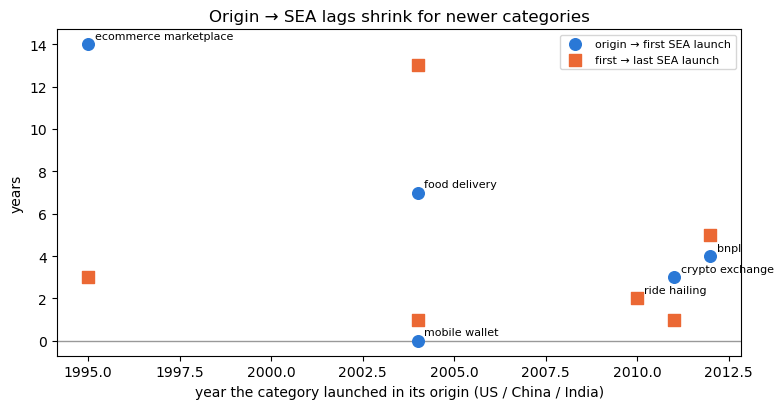

Spearman(origin year, origin→first-SEA lag) = -0.32 (n = 6, p = 0.538)


In [8]:
A = ATT["all dates"].reset_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(A.origin_year, A.lag_to_first_sea, s=70, color="#2a78d6", label="origin → first SEA launch", zorder=3)
ax.scatter(A.origin_year, A.sea_spread_years, s=70, marker="s", color="#eb6834", label="first → last SEA launch", zorder=3)
for _, r in A.iterrows():
    ax.annotate(r.category.replace("_", " "), (r.origin_year, r.lag_to_first_sea), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.axhline(0, color="#999", lw=1)
ax.set_xlabel("year the category launched in its origin (US / China / India)"); ax.set_ylabel("years")
ax.set_title("Origin → SEA lags shrink for newer categories"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "05_diffusion_speed.png", dpi=150); plt.show()
rho = stats.spearmanr(A.origin_year, A.lag_to_first_sea)
print(f"Spearman(origin year, origin→first-SEA lag) = {rho.correlation:.2f} (n = {len(A)}, p = {rho.pvalue:.3f})")

## 6 · Results summary
| Hypothesis | All dates | Verified only | Verdict |
|---|---|---|---|
| **H6a** China as often as US | US 3.5, China 1, India 1 (tie), SEA-native 1 (mobile wallets); binomial p = 0.63 | US 3, China 1, SEA-native 1; p = 0.63 | **Not rejected, but uninformative**: 4–5 categories cannot tell "equal" from "US-dominated" |
| **H6b** China-origin arrives faster | China lags median **3 yrs** vs US **8 yrs**; p = 0.005 | 3 vs 8; p = 0.004 | **Formally supported, not credible as a general rule**: the only China-origin category is crypto exchanges (one category, recent, and all SEA countries launched within a year) |
| **H7** consistent SEA order | Kendall's W = 0.16 (p = 0.56) | W = 0.24 (p = 0.43) | **Not supported**: no stable country order |
| **H7** SG or ID first | 3 of 6 vs 2.7 expected (p = 0.54) | 4 of 6 vs 3.3 (p = 0.41) | **Not supported** |

**What P5 does show (descriptive, with sources):**
* **Mobile wallets are SEA-native.** The Philippines' GCash (2004) launched in the same year as China's Alipay and
  years ahead of the US and India. Indonesia (T-Cash 2007) and Vietnam (MoMo 2010) followed.
* **Indonesia has the best average rank as an early mover** (first in e-commerce, BNPL and crypto exchanges, though not
  in a consistent order). **Different categories start in different countries**: ride-hailing in Malaysia (Grab's
  home), food delivery in Vietnam, wallets in the Philippines.
* **In the boom catalogue, the first *takeoffs* came from smaller markets**: Cambodia (mobile money 2011, fintech firm
  formation 2014), Vietnam (crypto firms 2014), Malaysia (fintech firms 2014). Indonesia was first only for mobile banking (2016).
* **Diffusion timing:** origin → first SEA launch ranges from 14 years (marketplaces, eBay 1995 → Tokopedia 2009) to
  2–4 years for later categories. The trend is downward but not significant with 6 categories (Spearman −0.32, p = 0.54).

**Limits:** launch ≠ takeoff; 6 categories; "first scaled app-based player" involves judgement where smaller local
players came earlier (e.g. Lelong in Malaysia, Tarad in Thailand, noted in the table).